In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import pandas as pd
from StatTools.analysis import dfa
from StatTools.analysis.dpcca import dpcca
from StatTools.experimental.augmentation.perturbations import add_exponential_gaps
from visualization_toolkit.styles.boxplot import (
    boxprops_filled,
    boxprops_filled_hatched,
)
import seaborn as sns
from research.kalman_filter.reconstruction_of_long_term_complex_system_dynamics.gen_filter_save import simulate_signal


## Generate gapped signals

In [2]:
ORIGINAL_SIGNALS_DIR = Path(
    "research/kalman_filter/reconstruction_of_long_term_complex_system_dynamics/data/model_signals"
)
OUTPUT_DIR = Path("research/kalman_filter/gaps_research/data/output")
H_LIST: list[float] = [0.7, 0.8, 0.9, 1.0]
SIGNALS_COUNT: int = 8
FILTER_ORDERS: list[int] = [2, 4, 12]
order_colors = {2: "tab:blue", 4: "tab:orange", 12: "tab:green"}
order_hatch = {2: "//", 4: "||", 12: "--"}
RQ_GAP_LIST = [10]
FG_GAP_LIST = [0.1]

tab_colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
    "tab:brown",
    "tab:pink",
]
markers = ["o", "^", "s", "*", "<", "P", ">"]

In [3]:
scales_full = np.array([2**i for i in range(3, 18)])
s_fit_shift = 7
scales_fit = scales_full[s_fit_shift:]
threads = 8

In [13]:
def _compute_h(sig, svalues=None):
    sig = np.array(sig)
    s_vals, f2_vals = dfa.dfa(sig, s_values=svalues, degree=2, processes=4)
    log_s = np.log(s_vals)
    log_f = np.log(np.sqrt(f2_vals))
    return round(
        stats.linregress(log_s, log_f).slope,
        3,
    )


def _compute_h_ff(s_vals, f_vals, start_inx=None, finish_inx=None):
    log_s = np.log(s_vals)
    log_f = np.log(f_vals)
    return round(
        stats.linregress(
            log_s[start_inx:finish_inx], log_f[start_inx:finish_inx]
        ).slope,
        3,
    )

In [14]:
def plot_ff(signal_loader, label_fn, save_name, show_fit_region=False, legend_fontsize=None):
    _, ax = plt.subplots(figsize=(6, 8))
    ff_mean = None
    for h_index, h_o in enumerate(H_LIST):
        signals = signal_loader(h_o)

        _, _, f2, s = dpcca(signals, 2, 1, scales_full, processes=threads, n_integral=1)

        diag_ff = np.diagonal(f2, axis1=1, axis2=2)
        diag_ff = np.where(diag_ff == 0, np.nan, diag_ff)

        ff = np.sqrt(diag_ff)
        ff /= ff[0, :]

        ff_mean = np.nanmean(ff, axis=1)
        sigma = np.nanstd(ff, axis=1)

        if show_fit_region:
            ax.axvspan(
                scales_fit[0] - 10**2 * 3,
                scales_fit[-1] + 10**5 / 2,
                facecolor="grey",
                alpha=0.1,
            )

        ax.plot(
            s,
            ff_mean,
            c=tab_colors[h_index + 2],
            label=label_fn(s, ff_mean),
        )
        ax.errorbar(
            s,
            ff_mean,
            yerr=2 * sigma,
            fmt="none",
            c=tab_colors[h_index + 2],
            capsize=4,
        )

    for i, H1 in enumerate([0.5, 0.6, 0.7, 0.8, 0.9, 1.0]):
        y0 = ff_mean[0]
        ref = y0 * (scales_full / scales_full[0]) ** H1

        plt.loglog(
            scales_full,
            ref,
            color=tab_colors[i],
            linestyle="--",
            label=f"$H=${H1}",
            alpha=0.5,
        )

    plt.grid(which="both")
    if legend_fontsize is not None:
        plt.legend(fontsize=legend_fontsize)
        plt.xticks(fontsize=legend_fontsize)
        plt.yticks(fontsize=legend_fontsize)
    else:
        plt.legend()

    # plt.savefig(OUTPUT_DATA_DIR / f"{save_name}.png", bbox_inches="tight")
    # plt.savefig(OUTPUT_DATA_DIR / f"{save_name}.svg", bbox_inches="tight")
    plt.show()

In [15]:
# # ~3 min
# plot_ff(
#     signal_loader=lambda h_o: np.array(
#         [
#             np.load(ORIGINAL_SIGNALS_DIR / f"original_hm{h_o}_{signal_idx}.npy")
#             for signal_idx in range(SIGNALS_COUNT)
#         ]
#     ),
#     label_fn=lambda s, ff_mean: f"$H_O=${_compute_h_ff(s[s_fit_shift:], ff_mean[s_fit_shift:]):.1f}",
#     save_name=None,
#     show_fit_region=True,
#     legend_fontsize=14,
# )

In [16]:
# params to distort the signal
rq = 10
fg = 0.4

In [17]:
# distort one original-gapped pair as an example
h_o_example = H_LIST[0]
signal_idx_example = 0

signal_o = np.load(
    ORIGINAL_SIGNALS_DIR / f"original_hm{h_o_example}_{signal_idx_example}.npy"
)
signal_g, gap_indices = add_exponential_gaps(signal_o, rq=rq, fg=fg)

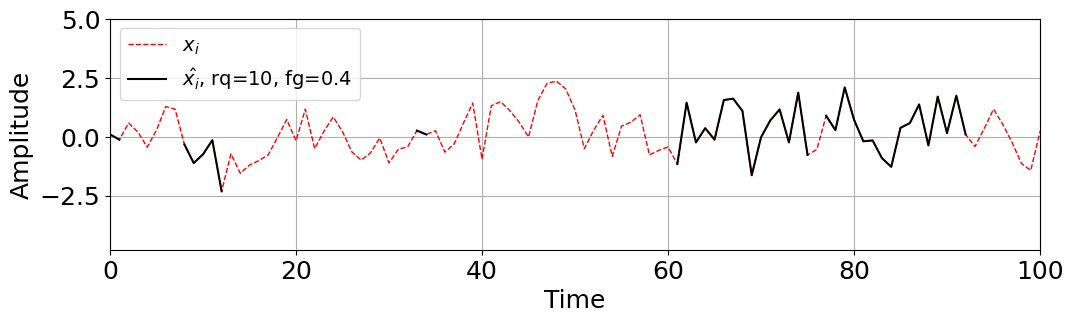

In [18]:
# plot the exaple of distortion
plt.figure(figsize=(12, 3))
plt.plot(
    signal_o,
    label="$x_i$",
    color="red",
    linestyle="--",
    linewidth=1,
)
plt.plot(signal_g, label=f"$\\hat{{x_i}}$, rq={rq}, fg={fg}", color="black")
plt.xlabel("Time", fontsize=18)
plt.ylabel("Amplitude", fontsize=18)
plt.legend(fontsize=14)
plt.tick_params(labelsize=18)
plt.grid(True)
plt.xlim(0, 100)
plt.show()

## Filter one signal_g

In [ ]:
# ~ 2 min
rng = np.random.default_rng(0)
tiny_noise = rng.normal(0, np.nanstd(signal_o) * 1e-6, size=signal_g.shape)

signal_filtered = {
    order: simulate_signal(signal_g, tiny_noise, h_o_example, "Kasdin", order, seed=0)
    for order in FILTER_ORDERS
}

In [20]:
def get_rq(signal):
    signal = signal - np.nanmedian(signal)
    crossings = []
    for i in range(1, len(signal)):
        if (signal[i - 1] < 0 and signal[i] >= 0):
            crossings.append(i)
    r = np.diff(np.array(crossings)).astype(float)
    return np.mean(r)

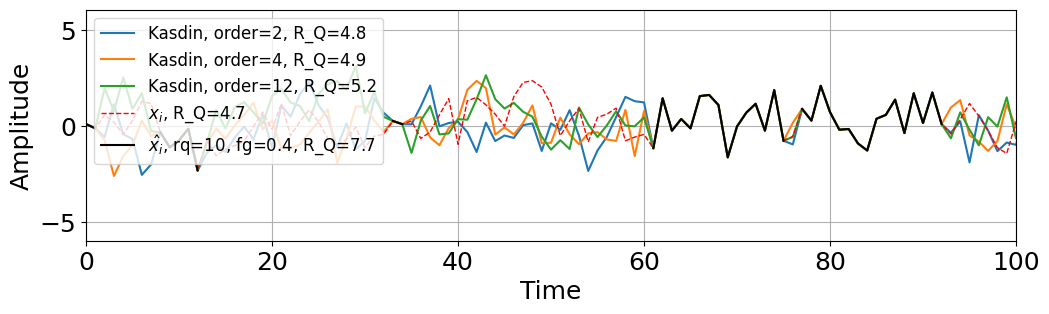

In [22]:
plt.figure(figsize=(12, 3))
for order in FILTER_ORDERS:
    plt.plot(
        signal_filtered[order],
        label=f"Kasdin, order={order}, R_Q={get_rq(signal_filtered[order]):.1f}",
        color=order_colors[order],
    )
plt.plot(
    signal_o,
    label=f"$x_i$, R_Q={get_rq(signal_o):.1f}",
    color="red",
    linestyle="--",
    linewidth=1,
)
plt.plot(
    signal_g,
    label=f"$\\hat{{x_i}}$, rq={rq}, fg={fg}, R_Q={get_rq(signal_g):.1f}",
    color="black",
    # alpha=0.4, 
)
plt.xlabel("Time", fontsize=18)
plt.ylabel("Amplitude", fontsize=18)
plt.legend(fontsize=12)
plt.tick_params(labelsize=18)
plt.grid(True)
plt.xlim(0, 100)
plt.show()

/var/folders/72/b2t6g2j111q_wmvh2pm885t00000gn/T/ipykernel_51974/8716944.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12)


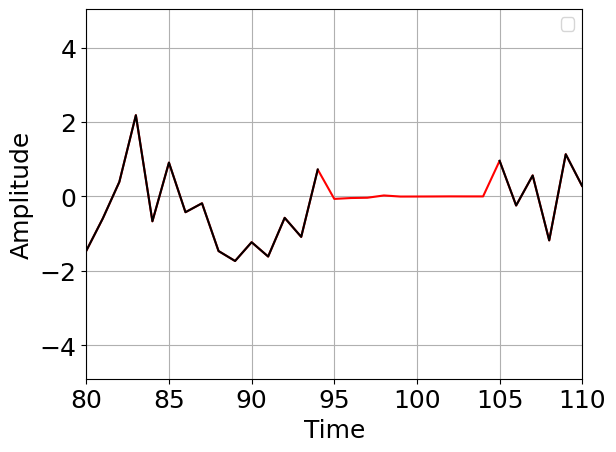

In [35]:
signal_g = np.load("research/kalman_filter/gaps_research/data/model_signals_gaps/gapped_hm0.7_4_rq50_fg0.05.npy")
signal_mar = np.load("research/kalman_filter/gaps_research/data/model_signals_gaps/reconstructed_hm0.7_4_rq50_fg0.05_d2.npy")

plt.plot(
    signal_mar,
    color="red",
    # alpha=0.4, 
)
plt.plot(
    signal_g,
    color="black",
    # alpha=0.4, 
)
plt.xlabel("Time", fontsize=18)
plt.ylabel("Amplitude", fontsize=18)
plt.legend(fontsize=12)
plt.tick_params(labelsize=18)
plt.grid(True)
plt.xlim(80, 110)
plt.show()

## Collect stats

### Kasdin

In [4]:
GAPS_DIR = Path(
    "research/kalman_filter/gaps_research/data"
)
metrics_df = pd.read_csv(GAPS_DIR / "metrics_rq_Kasdin.csv", index_col=0) # data obtained by gen_gap_reconstruction.py

In [5]:
metrics_df

,signal_idx,rq_gap,fg_gap,order,rq_original,rq_gapped,rq_reconstructed,rmse_gap,method
model_h,,,,,,,,,
0.7,0,5,0.05,2,4.749647,5.006302,4.733651,1.386293,Kasdin
0.7,0,5,0.05,4,4.749647,5.006302,4.746207,1.385698,Kasdin
0.7,0,5,0.05,12,4.749647,5.006302,4.755808,1.417313,Kasdin
0.7,0,100,0.10,2,4.749647,5.294471,4.757189,1.443540,Kasdin
0.7,0,100,0.10,4,4.749647,5.294471,4.802640,1.476451,Kasdin
...,...,...,...,...,...,...,...,...,...
1.0,7,100,0.30,4,10.699135,14.620977,10.173261,1.840356,Kasdin
1.0,7,100,0.30,12,10.699135,14.620977,11.170797,2.418717,Kasdin
1.0,7,100,0.10,2,10.699135,11.920850,10.127668,1.577647,Kasdin


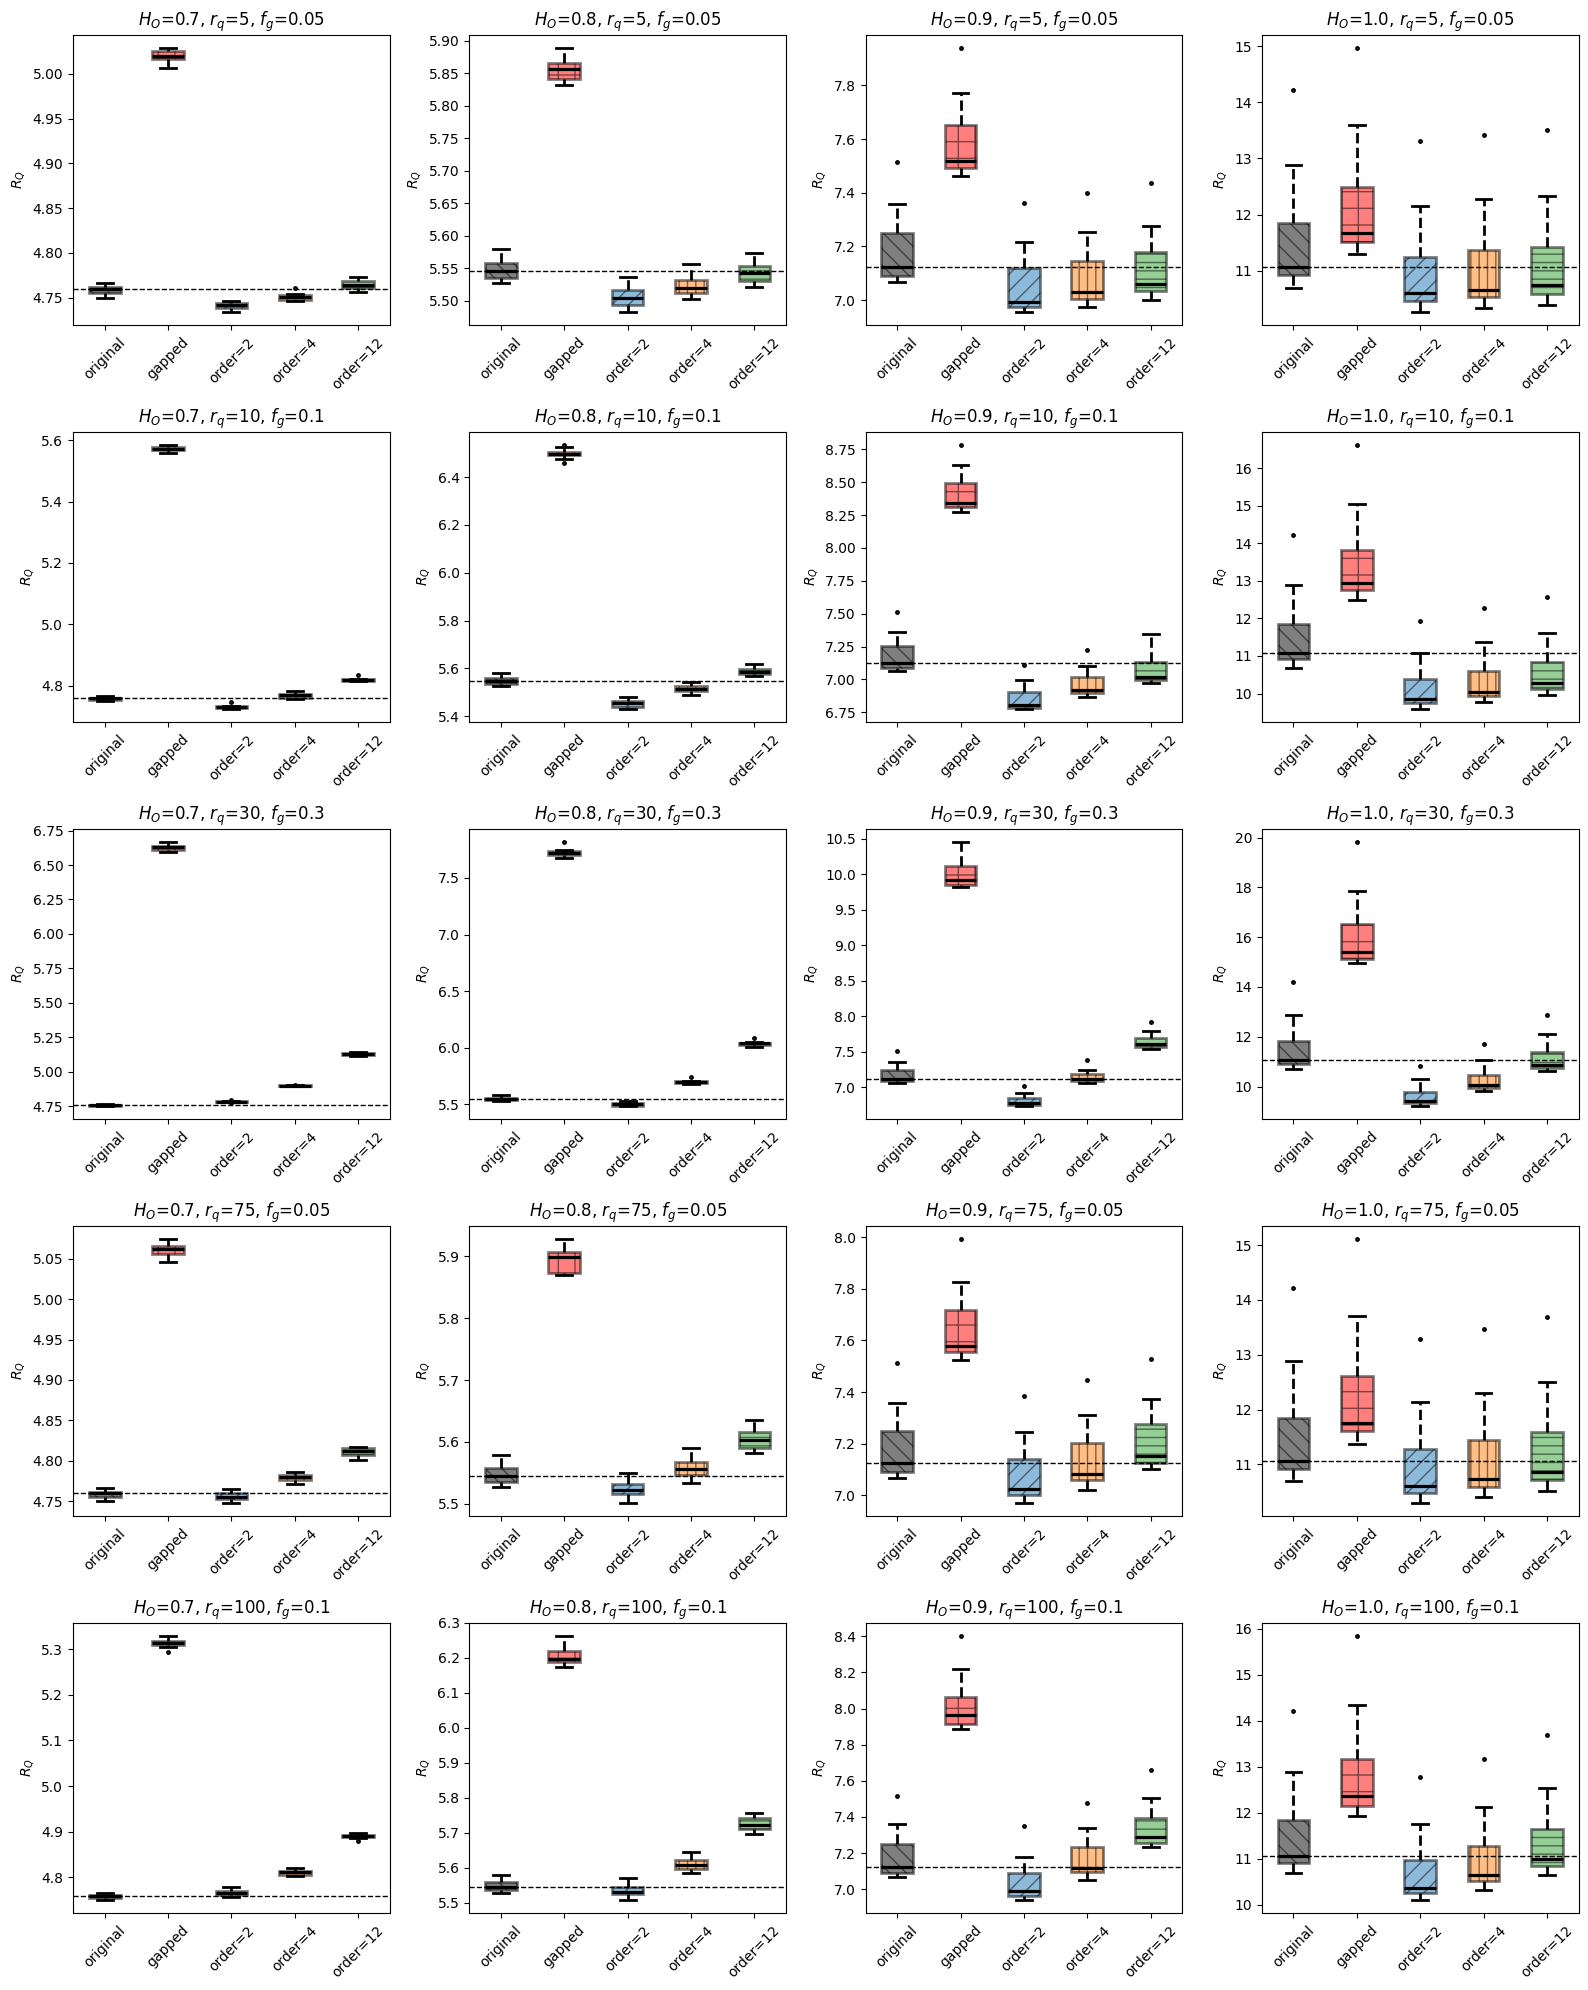

In [6]:
df = metrics_df.reset_index()

box_colors = {"original": "black", "gapped": "red"}
box_colors.update({f"order={o}": order_colors[o] for o in FILTER_ORDERS})
box_hatch = {"original": "\\\\", "gapped": "+"}
box_hatch.update({f"order={o}": order_hatch[o] for o in FILTER_ORDERS})

h_values = sorted(df["model_h"].unique())
rqfg_values = sorted(
    df[["rq_gap", "fg_gap"]].drop_duplicates().itertuples(index=False, name=None)
)[::4]

n_rows = len(rqfg_values)
n_cols = len(h_values)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=False, squeeze=False
)

for row, (rq_gap, fg_gap) in enumerate(rqfg_values):
    for col, model_h in enumerate(h_values):
        ax = axes[row, col]
        group = df[
            (df["model_h"] == model_h)
            & (df["rq_gap"] == rq_gap)
            & (df["fg_gap"] == fg_gap)
        ]

        per_signal = group.drop_duplicates("signal_idx")
        data = [per_signal["rq_original"], per_signal["rq_gapped"]]
        labels = ["original", "gapped"]
        for order in FILTER_ORDERS:
            data.append(group.loc[group["order"] == order, "rq_reconstructed"])
            labels.append(f"order={order}")

        bplot = ax.boxplot(data, tick_labels=labels, **boxprops_filled_hatched())
        for patch, label in zip(bplot["boxes"], labels):
            patch.set_facecolor(box_colors[label])
            patch.set_hatch(box_hatch[label])
            patch.set_alpha(0.5)

        ax.axhline(per_signal["rq_original"].median(), color="k", linestyle="--", linewidth=1)

        ax.set_title(f"$H_O$={model_h}, $r_q$={rq_gap}, $f_g$={fg_gap}")
        ax.set_ylabel("$R_Q$")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [7]:
df = metrics_df.reset_index()
df["rq_x_fg_gap"] = df["rq_gap"] * df["fg_gap"]
df["rq_error"] = df["rq_reconstructed"] / df["rq_original"]
# df["rq_error"] = (1 - df["rq_reconstructed"] / df["rq_original"])**2

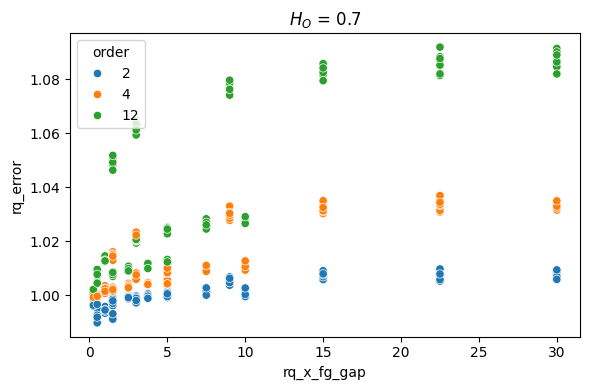

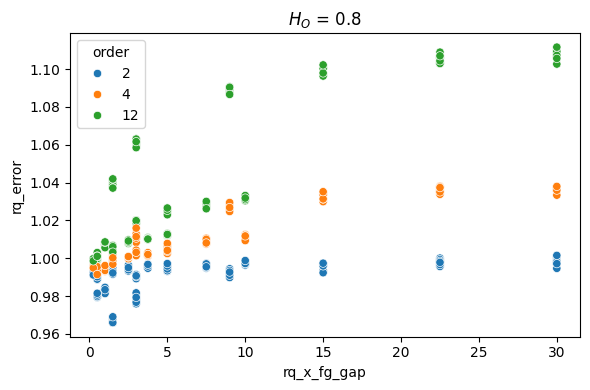

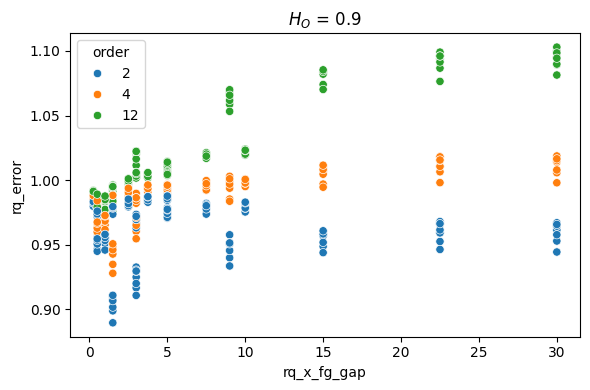

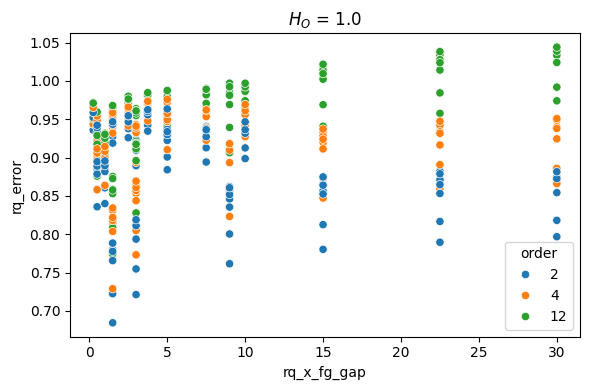

In [8]:
for h_value, group in df.groupby("model_h"):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(
        data=group,
        x="rq_x_fg_gap",
        y="rq_error",
        hue="order",
        palette=sns.color_palette(n_colors=3)
    )
    # plt.yscale("log")
    # plt.xscale("log")
    plt.title(f"$H_O$ = {h_value}")
    plt.tight_layout()
    filepath = OUTPUT_DIR / f"scatter_model_h_{h_value}.png"
    plt.savefig(filepath, dpi=150)
    plt.show()

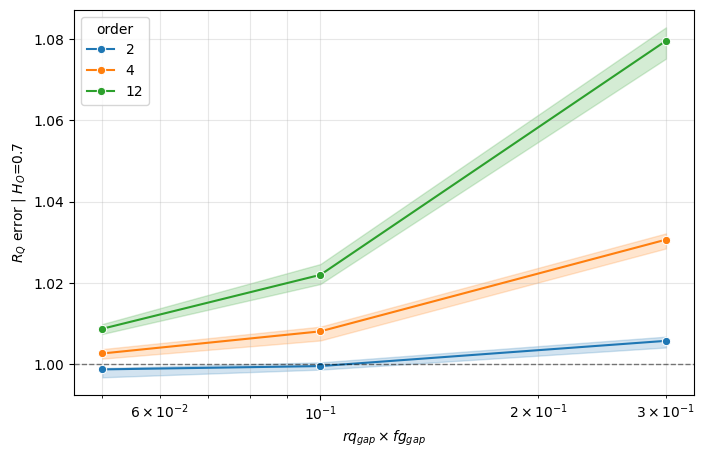

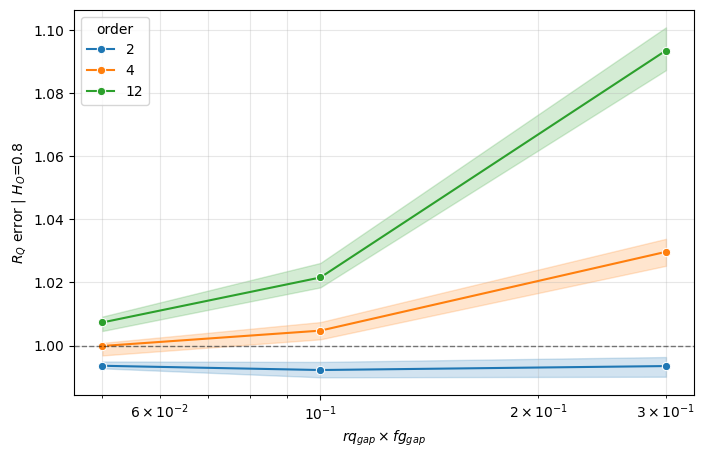

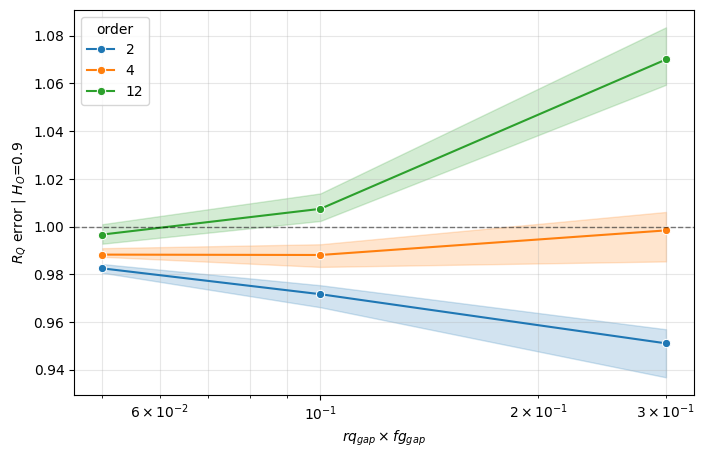

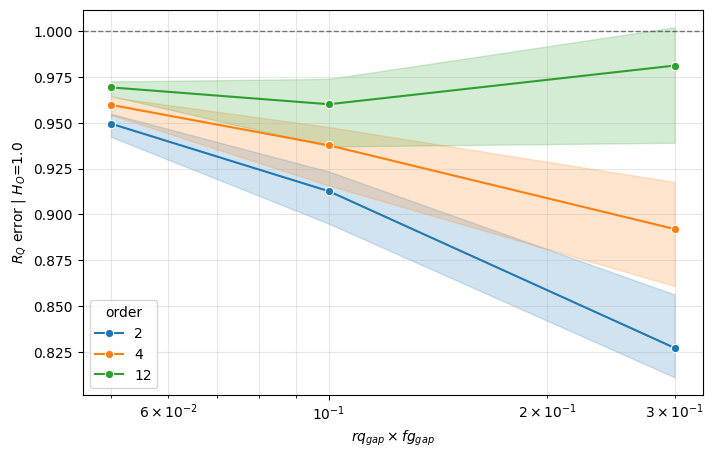

In [11]:
for h_value, group in df.groupby("model_h"):
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=group,
        x="fg_gap",
        y="rq_error",
        hue="order",
        palette=sns.color_palette(n_colors=3),
        marker="o",
        estimator="median",
        # errorbar=("pi", 50),
    )
    plt.xscale("log")
    # plt.yscale("log")
    plt.axhline(1.0, color="k", linestyle="--", linewidth=1, alpha=0.5)
    plt.xlabel(r"$rq_{gap} \times fg_{gap}$")
    # plt.ylabel(r"$\hat{R}_Q / R_Q$")
    plt.ylabel(fr"$R_Q$ error | $H_O$={h_value}")
    plt.grid(True, which="both", alpha=0.3)
    filepath = OUTPUT_DIR / f"kasdin-rq_error_model_h_{h_value}.png"
    plt.savefig(filepath, dpi=150)
    plt.show()

/var/folders/72/b2t6g2j111q_wmvh2pm885t00000gn/T/ipykernel_51974/2626148106.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.lineplot(


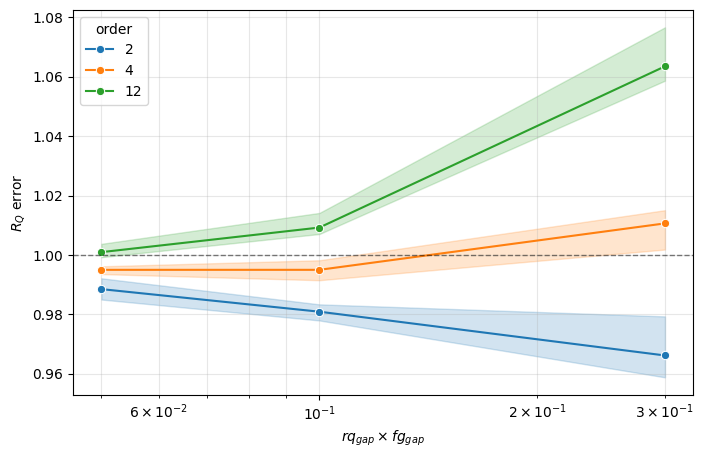

In [13]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df,
    x="fg_gap",
    y="rq_error",
    hue="order",
    palette=sns.color_palette(),
    marker="o",
    estimator="median",
    # errorbar=("pi", 50),
)
plt.xscale("log")
# plt.yscale("log")
plt.axhline(1.0, color="k", linestyle="--", linewidth=1, alpha=0.5)
plt.xlabel(r"$rq_{gap} \times fg_{gap}$")
# plt.ylabel(r"$\hat{R}_Q / R_Q$")
plt.ylabel(r"$R_Q$ error")
plt.grid(True, which="both", alpha=0.3)
filepath = OUTPUT_DIR / "kasdin-rq_error.png"
plt.savefig(filepath, dpi=150)
plt.show()

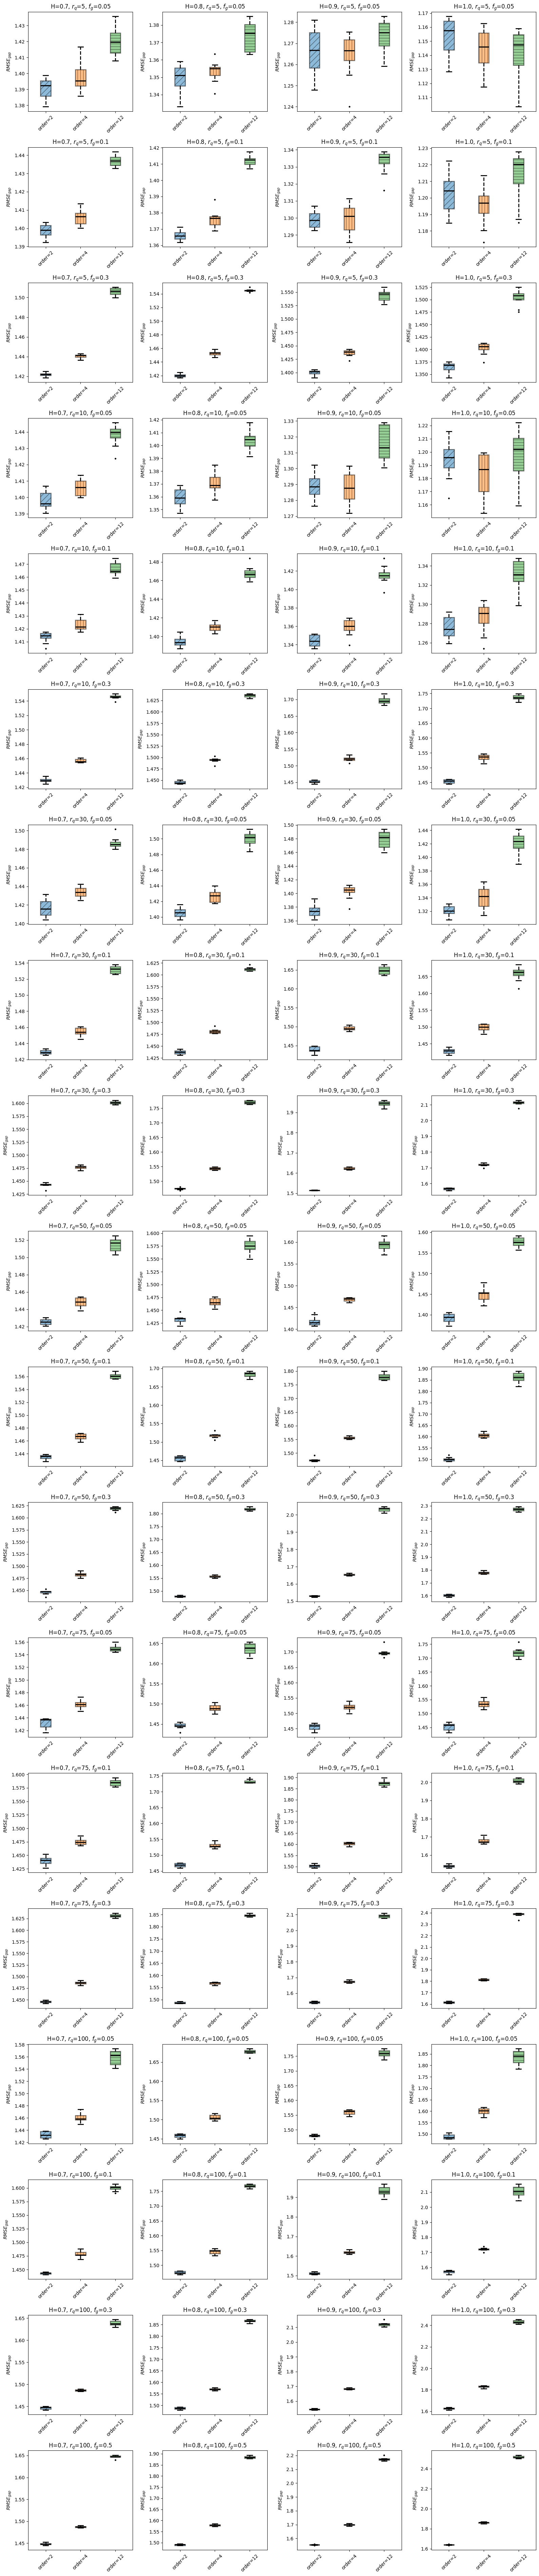

In [57]:
df = metrics_df.reset_index()

box_colors = {"original": "black", "gapped": "red"}
box_colors.update({f"order={o}": order_colors[o] for o in FILTER_ORDERS})
box_hatch = {"original": "\\\\", "gapped": "+"}
box_hatch.update({f"order={o}": order_hatch[o] for o in FILTER_ORDERS})

h_values = sorted(df["model_h"].unique())
rqfg_values = sorted(
    df[["rq_gap", "fg_gap"]].drop_duplicates().itertuples(index=False, name=None)
)

n_rows = len(rqfg_values)
n_cols = len(h_values)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=False, squeeze=False
)

for row, (rq_gap, fg_gap) in enumerate(rqfg_values):
    for col, model_h in enumerate(h_values):
        ax = axes[row, col]
        group = df[
            (df["model_h"] == model_h)
            & (df["rq_gap"] == rq_gap)
            & (df["fg_gap"] == fg_gap)
        ]

        data = []
        labels = []
        for order in FILTER_ORDERS:
            data.append(group.loc[group["order"] == order, "rmse_gap"])
            labels.append(f"order={order}")

        bplot = ax.boxplot(data, tick_labels=labels, **boxprops_filled_hatched())
        for patch, label in zip(bplot["boxes"], labels):
            patch.set_facecolor(box_colors[label])
            patch.set_hatch(box_hatch[label])
            patch.set_alpha(0.5)

        ax.set_title(f"H={model_h}, $r_q$={rq_gap}, $f_g$={fg_gap}")
        ax.set_ylabel("$RMSE_{gap}$")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### YW

In [14]:
GAPS_DIR = Path(
    "research/kalman_filter/gaps_research/data"
)
metrics_df = pd.read_csv(GAPS_DIR / "metrics_rq_YW.csv", index_col=0) # data obtained by gen_gap_reconstruction.py

In [15]:
metrics_df

,signal_idx,rq_gap,fg_gap,order,rq_original,rq_gapped,rq_reconstructed,rmse_gap,method
model_h,,,,,,,,,
0.7,0,5,0.05,2,4.749647,5.006302,4.728102,1.383907,YW
0.7,0,5,0.05,4,4.749647,5.006302,4.731729,1.373204,YW
0.7,0,5,0.05,12,4.749647,5.006302,4.727718,1.382070,YW
0.7,0,10,0.05,2,4.749647,5.143528,4.725885,1.403236,YW
0.7,0,10,0.05,4,4.749647,5.143528,4.721204,1.391604,YW
...,...,...,...,...,...,...,...,...,...
1.0,7,100,0.30,4,10.699135,14.620977,10.526423,2.035308,YW
1.0,7,100,0.30,12,10.699135,14.620977,10.215483,1.809996,YW
1.0,7,75,0.30,2,10.699135,14.668429,10.562049,2.046710,YW


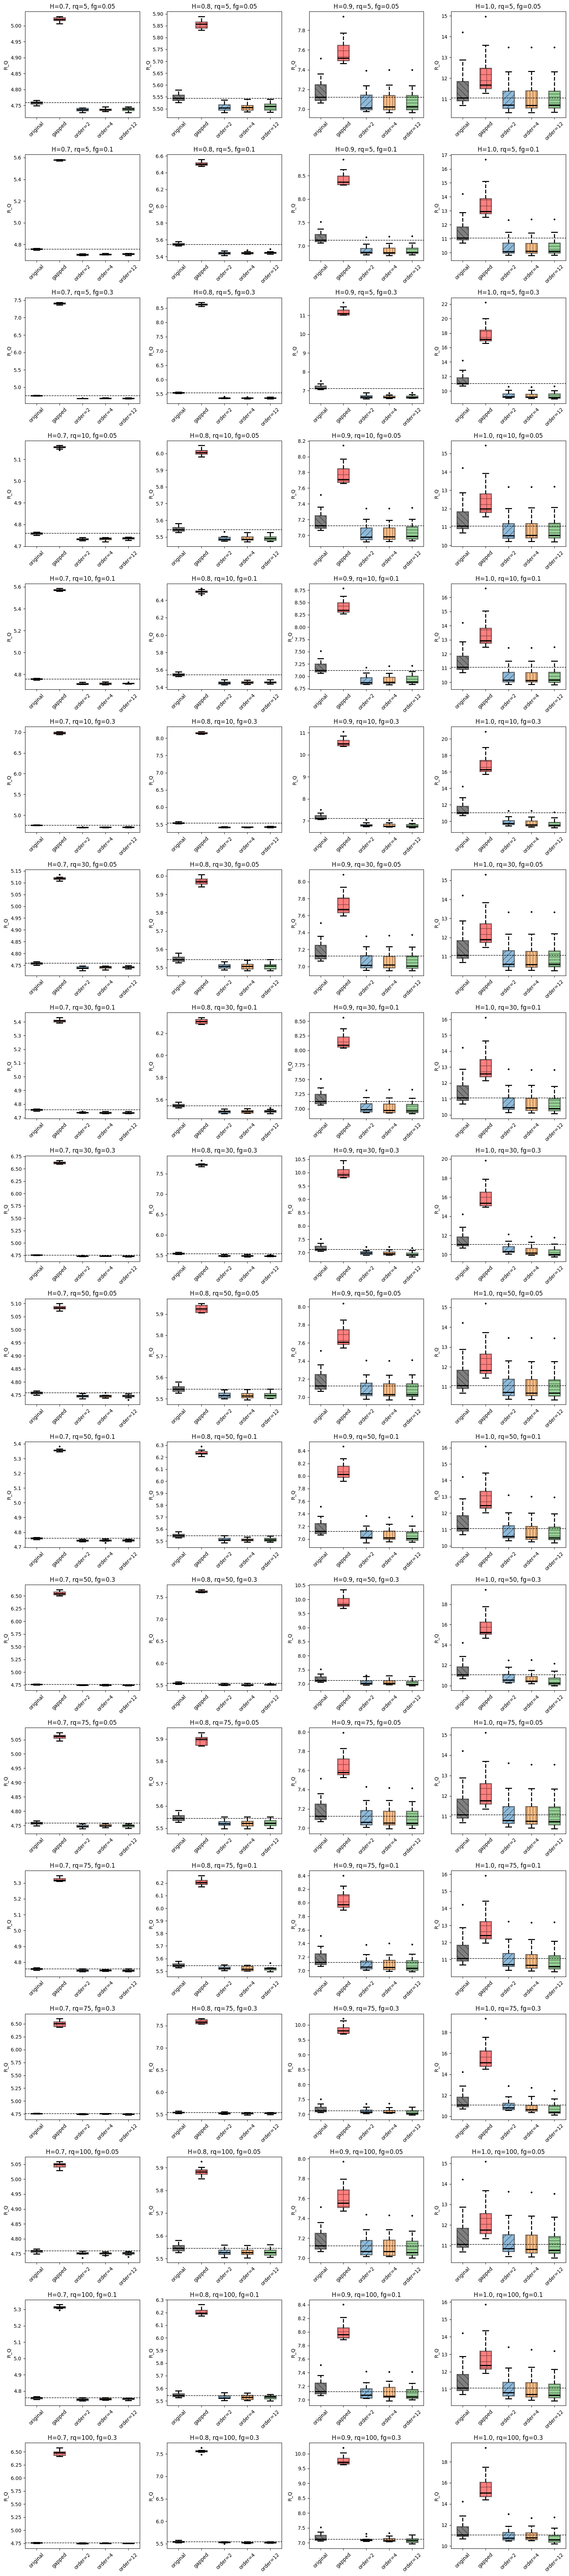

In [16]:
df = metrics_df.reset_index()

box_colors = {"original": "black", "gapped": "red"}
box_colors.update({f"order={o}": order_colors[o] for o in FILTER_ORDERS})
box_hatch = {"original": "\\\\", "gapped": "+"}
box_hatch.update({f"order={o}": order_hatch[o] for o in FILTER_ORDERS})

h_values = sorted(df["model_h"].unique())
rqfg_values = sorted(
    df[["rq_gap", "fg_gap"]].drop_duplicates().itertuples(index=False, name=None)
)

n_rows = len(rqfg_values)
n_cols = len(h_values)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=False, squeeze=False
)

for row, (rq_gap, fg_gap) in enumerate(rqfg_values):
    for col, model_h in enumerate(h_values):
        ax = axes[row, col]
        group = df[
            (df["model_h"] == model_h)
            & (df["rq_gap"] == rq_gap)
            & (df["fg_gap"] == fg_gap)
        ]

        per_signal = group.drop_duplicates("signal_idx")
        data = [per_signal["rq_original"], per_signal["rq_gapped"]]
        labels = ["original", "gapped"]
        for order in FILTER_ORDERS:
            data.append(group.loc[group["order"] == order, "rq_reconstructed"])
            labels.append(f"order={order}")

        bplot = ax.boxplot(data, tick_labels=labels, **boxprops_filled_hatched())
        for patch, label in zip(bplot["boxes"], labels):
            patch.set_facecolor(box_colors[label])
            patch.set_hatch(box_hatch[label])
            patch.set_alpha(0.5)

        ax.axhline(per_signal["rq_original"].median(), color="k", linestyle="--", linewidth=1)

        ax.set_title(f"H={model_h}, rq={rq_gap}, fg={fg_gap}")
        ax.set_ylabel("R_Q")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [17]:
df = metrics_df.reset_index()
df["rq_x_fg_gap"] = df["rq_gap"] * df["fg_gap"]
df["rq_error"] = df["rq_reconstructed"] / df["rq_original"]
# df["rq_error"] = (1 - df["rq_reconstructed"] / df["rq_original"])**2

/var/folders/72/b2t6g2j111q_wmvh2pm885t00000gn/T/ipykernel_51974/2131309094.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.lineplot(


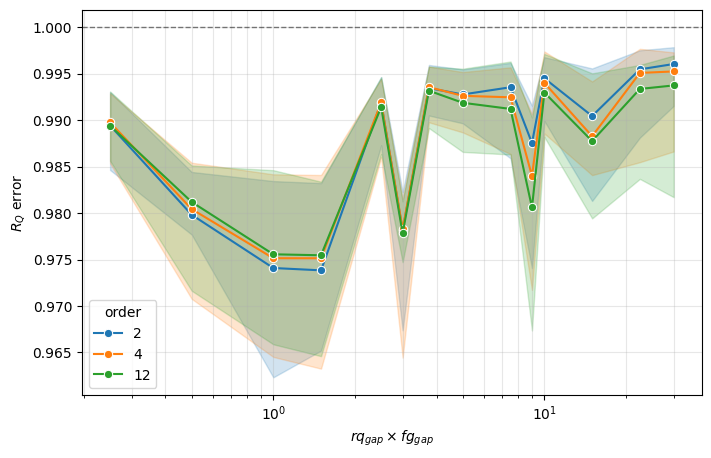

In [18]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df,
    x="rq_x_fg_gap",
    y="rq_error",
    hue="order",
    palette=sns.color_palette(),
    marker="o",
    estimator="median",
    # errorbar=("pi", 50),
)
plt.xscale("log")
plt.axhline(1.0, color="k", linestyle="--", linewidth=1, alpha=0.5)
plt.xlabel(r"$rq_{gap} \times fg_{gap}$")
# plt.ylabel(r"$\hat{R}_Q / R_Q$")
plt.ylabel(r"$R_Q$ error")
plt.grid(True, which="both", alpha=0.3)
filepath = OUTPUT_DIR / "yw-rq_error.png"
plt.savefig(filepath, dpi=150)
plt.show()

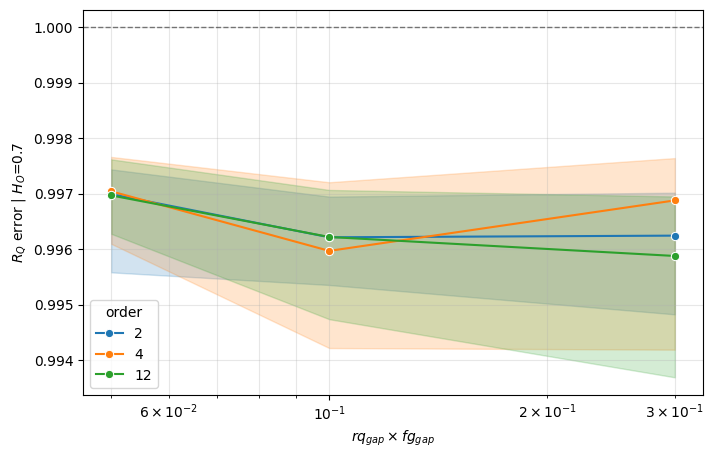

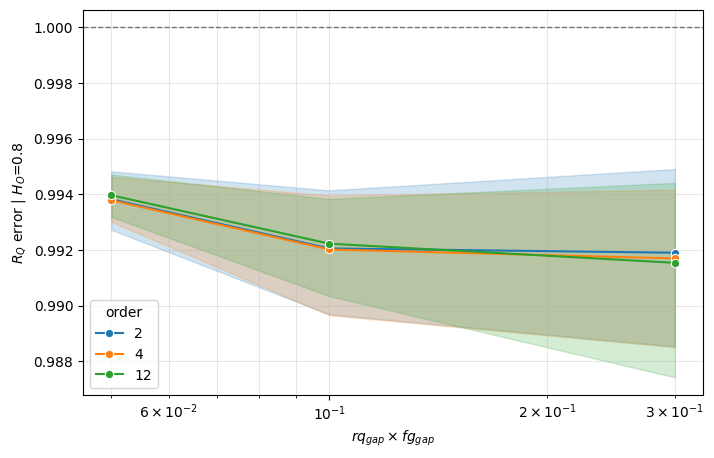

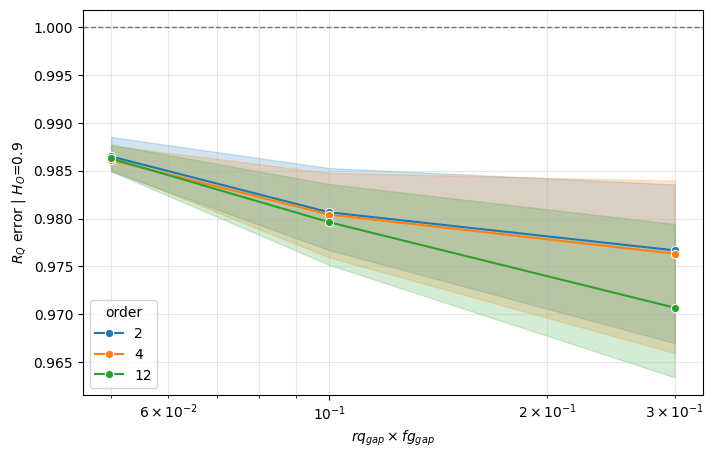

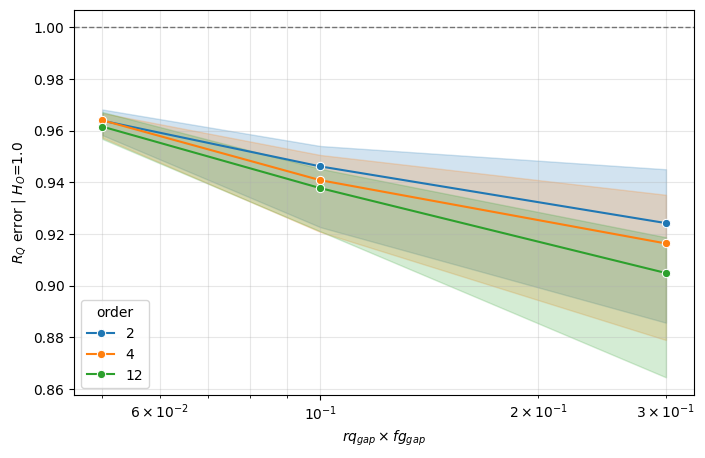

In [20]:
for h_value, group in df.groupby("model_h"):
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=group,
        x="fg_gap",
        y="rq_error",
        hue="order",
        palette=sns.color_palette(n_colors=3),
        marker="o",
        estimator="median",
        # errorbar=("pi", 50),
    )
    plt.xscale("log")
    # plt.yscale("log")
    plt.axhline(1.0, color="k", linestyle="--", linewidth=1, alpha=0.5)
    plt.xlabel(r"$rq_{gap} \times fg_{gap}$")
    # plt.ylabel(r"$\hat{R}_Q / R_Q$")
    plt.ylabel(fr"$R_Q$ error | $H_O$={h_value}")
    plt.grid(True, which="both", alpha=0.3)
    filepath = OUTPUT_DIR / f"yw-rq_error_model_h_{h_value}.png"
    plt.savefig(filepath, dpi=150)
    plt.show()

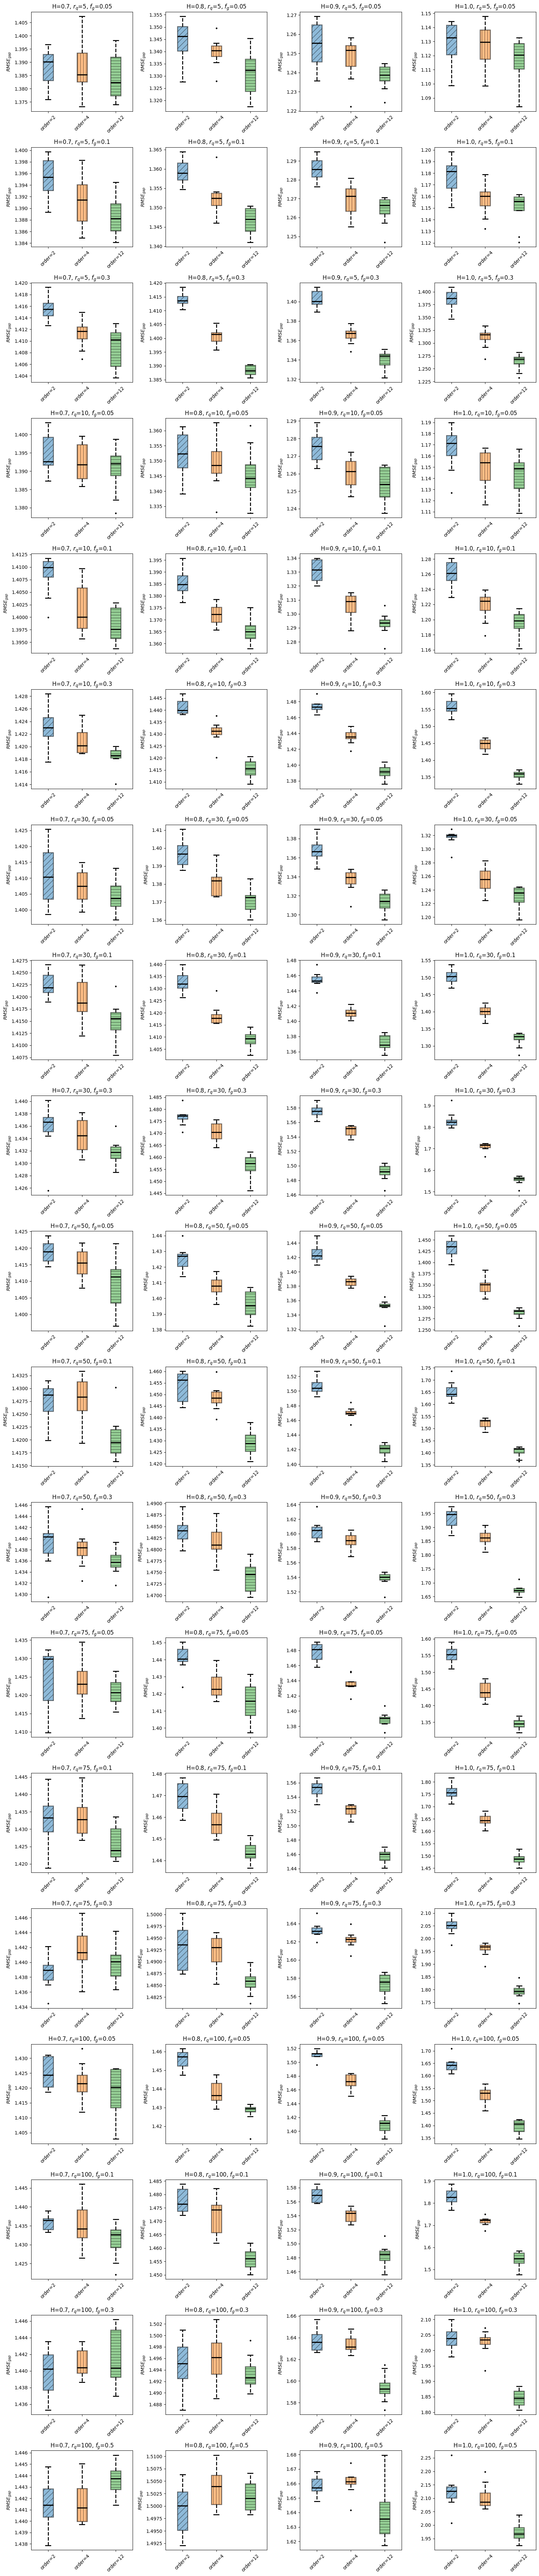

In [ ]:
df = metrics_df.reset_index()

box_colors = {"original": "black", "gapped": "red"}
box_colors.update({f"order={o}": order_colors[o] for o in FILTER_ORDERS})
box_hatch = {"original": "\\\\", "gapped": "+"}
box_hatch.update({f"order={o}": order_hatch[o] for o in FILTER_ORDERS})

h_values = sorted(df["model_h"].unique())
rqfg_values = sorted(
    df[["rq_gap", "fg_gap"]].drop_duplicates().itertuples(index=False, name=None)
)[::4]

n_rows = len(rqfg_values)
n_cols = len(h_values)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=False, squeeze=False
)

for row, (rq_gap, fg_gap) in enumerate(rqfg_values):
    for col, model_h in enumerate(h_values):
        ax = axes[row, col]
        group = df[
            (df["model_h"] == model_h)
            & (df["rq_gap"] == rq_gap)
            & (df["fg_gap"] == fg_gap)
        ]

        data = []
        labels = []
        for order in FILTER_ORDERS:
            data.append(group.loc[group["order"] == order, "rmse_gap"])
            labels.append(f"order={order}")

        bplot = ax.boxplot(data, tick_labels=labels, **boxprops_filled_hatched())
        for patch, label in zip(bplot["boxes"], labels):
            patch.set_facecolor(box_colors[label])
            patch.set_hatch(box_hatch[label])
            patch.set_alpha(0.5)

        ax.set_title(f"H={model_h}, $r_q$={rq_gap}, $f_g$={fg_gap}")
        ax.set_ylabel("$RMSE_{gap}$")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

/var/folders/72/b2t6g2j111q_wmvh2pm885t00000gn/T/ipykernel_37692/3733213052.py:2: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  sns.lineplot(


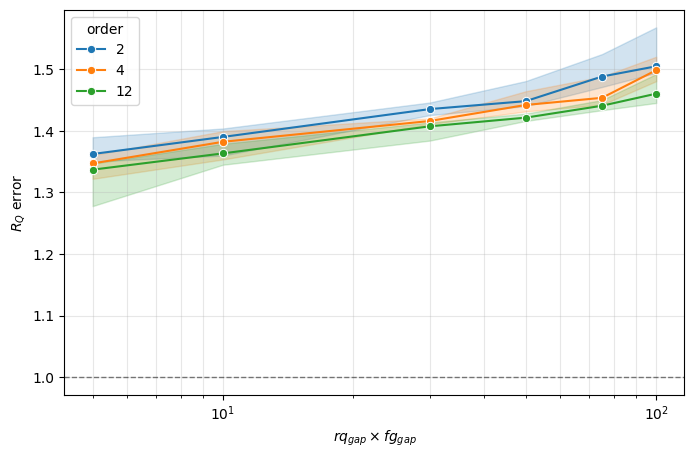

In [73]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df,
    x="rq_gap",
    y="rmse_gap",
    hue="order",
    palette=sns.color_palette(),
    marker="o",
    estimator="median",
    # errorbar=("pi", 50),
)
plt.xscale("log")
# plt.yscale("log")
plt.axhline(1.0, color="k", linestyle="--", linewidth=1, alpha=0.5)
plt.xlabel(r"$rq_{gap} \times fg_{gap}$")
# plt.ylabel(r"$\hat{R}_Q / R_Q$")
plt.ylabel(r"$R_Q$ error")
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Compare YW and Kasdin

In [27]:
yw_metrics_df = pd.read_csv(GAPS_DIR / "metrics_rq_YW.csv", index_col=0) # data obtained by gen_gap_reconstruction.py
kasdin_metrics_df = pd.read_csv(GAPS_DIR / "metrics_rq_Kasdin.csv", index_col=0) # data obtained by gen_gap_reconstruction.py
mar_metrics_df = pd.read_csv(GAPS_DIR / "metrics_rq_mar.csv", index_col=0) # data obtained by gen_gap_reconstruction.py

combined_df = pd.concat([yw_metrics_df, kasdin_metrics_df, mar_metrics_df])
# mar has no `order` column (uses `n_levels` instead) - treat n_levels as its order
combined_df["order"] = combined_df["order"].fillna(combined_df["n_levels"]).astype(int)

#### RQ

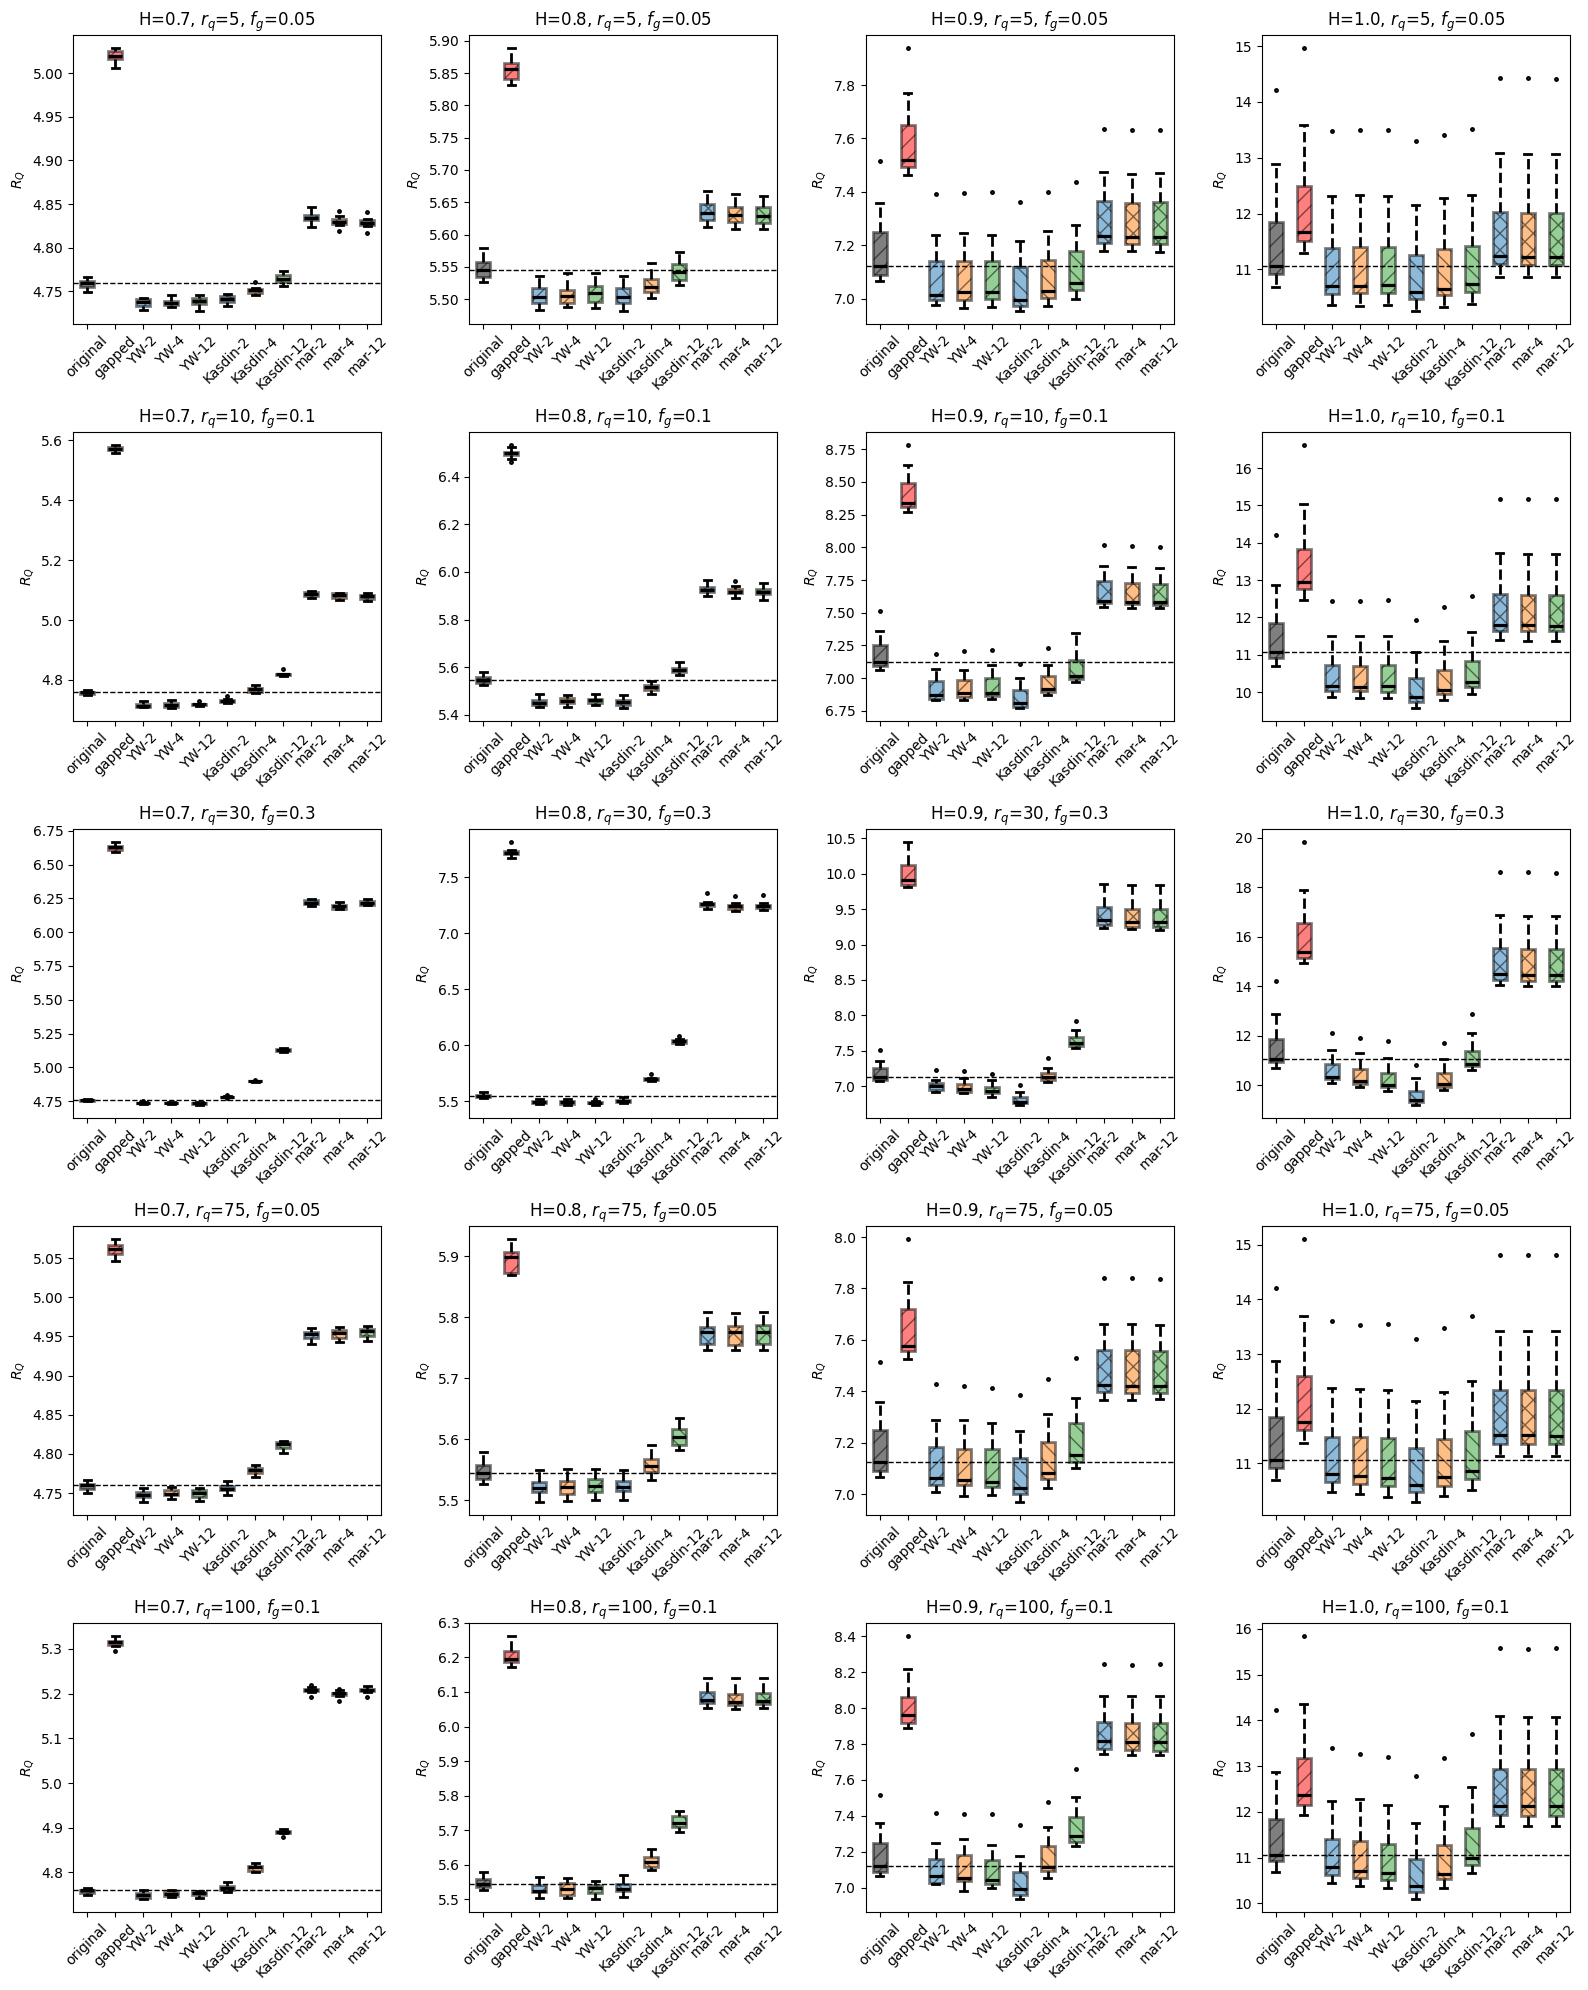

In [28]:
df = combined_df.reset_index()

box_colors = {"original": "black", "gapped": "red"}
box_colors.update({f"order={o}": order_colors[o] for o in FILTER_ORDERS})
method_hatch = {"YW": "//", "Kasdin": "\\\\", "mar": "xx"}
methods = ["YW", "Kasdin", "mar"]

h_values = sorted(df["model_h"].unique())
rqfg_values = sorted(
    df[["rq_gap", "fg_gap"]].drop_duplicates().itertuples(index=False, name=None)
)[::4]

n_rows = len(rqfg_values)
n_cols = len(h_values)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=False, squeeze=False
)

for row, (rq_gap, fg_gap) in enumerate(rqfg_values):
    for col, model_h in enumerate(h_values):
        ax = axes[row, col]
        group = df[
            (df["model_h"] == model_h)
            & (df["rq_gap"] == rq_gap)
            & (df["fg_gap"] == fg_gap)
        ]

        per_signal = group.drop_duplicates("signal_idx")
        data = [per_signal["rq_original"], per_signal["rq_gapped"]]
        labels = ["original", "gapped"]
        colors = [box_colors["original"], box_colors["gapped"]]
        hatches = [None, None]
        for method in methods:
            for order in FILTER_ORDERS:
                sub = group[(group["order"] == order) & (group["method"] == method)]
                data.append(sub["rq_reconstructed"])
                labels.append(f"{method}-{order}")
                colors.append(box_colors[f"order={order}"])
                hatches.append(method_hatch[method])

        bplot = ax.boxplot(data, tick_labels=labels, **boxprops_filled_hatched())
        for patch, color, hatch in zip(bplot["boxes"], colors, hatches):
            patch.set_facecolor(color)
            if hatch is not None:
                patch.set_hatch(hatch)
            patch.set_alpha(0.5)

        ax.axhline(per_signal["rq_original"].median(), color="k", linestyle="--", linewidth=1)

        ax.set_title(f"H={model_h}, $r_q$={rq_gap}, $f_g$={fg_gap}")
        ax.set_ylabel("$R_Q$")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


#### MSE

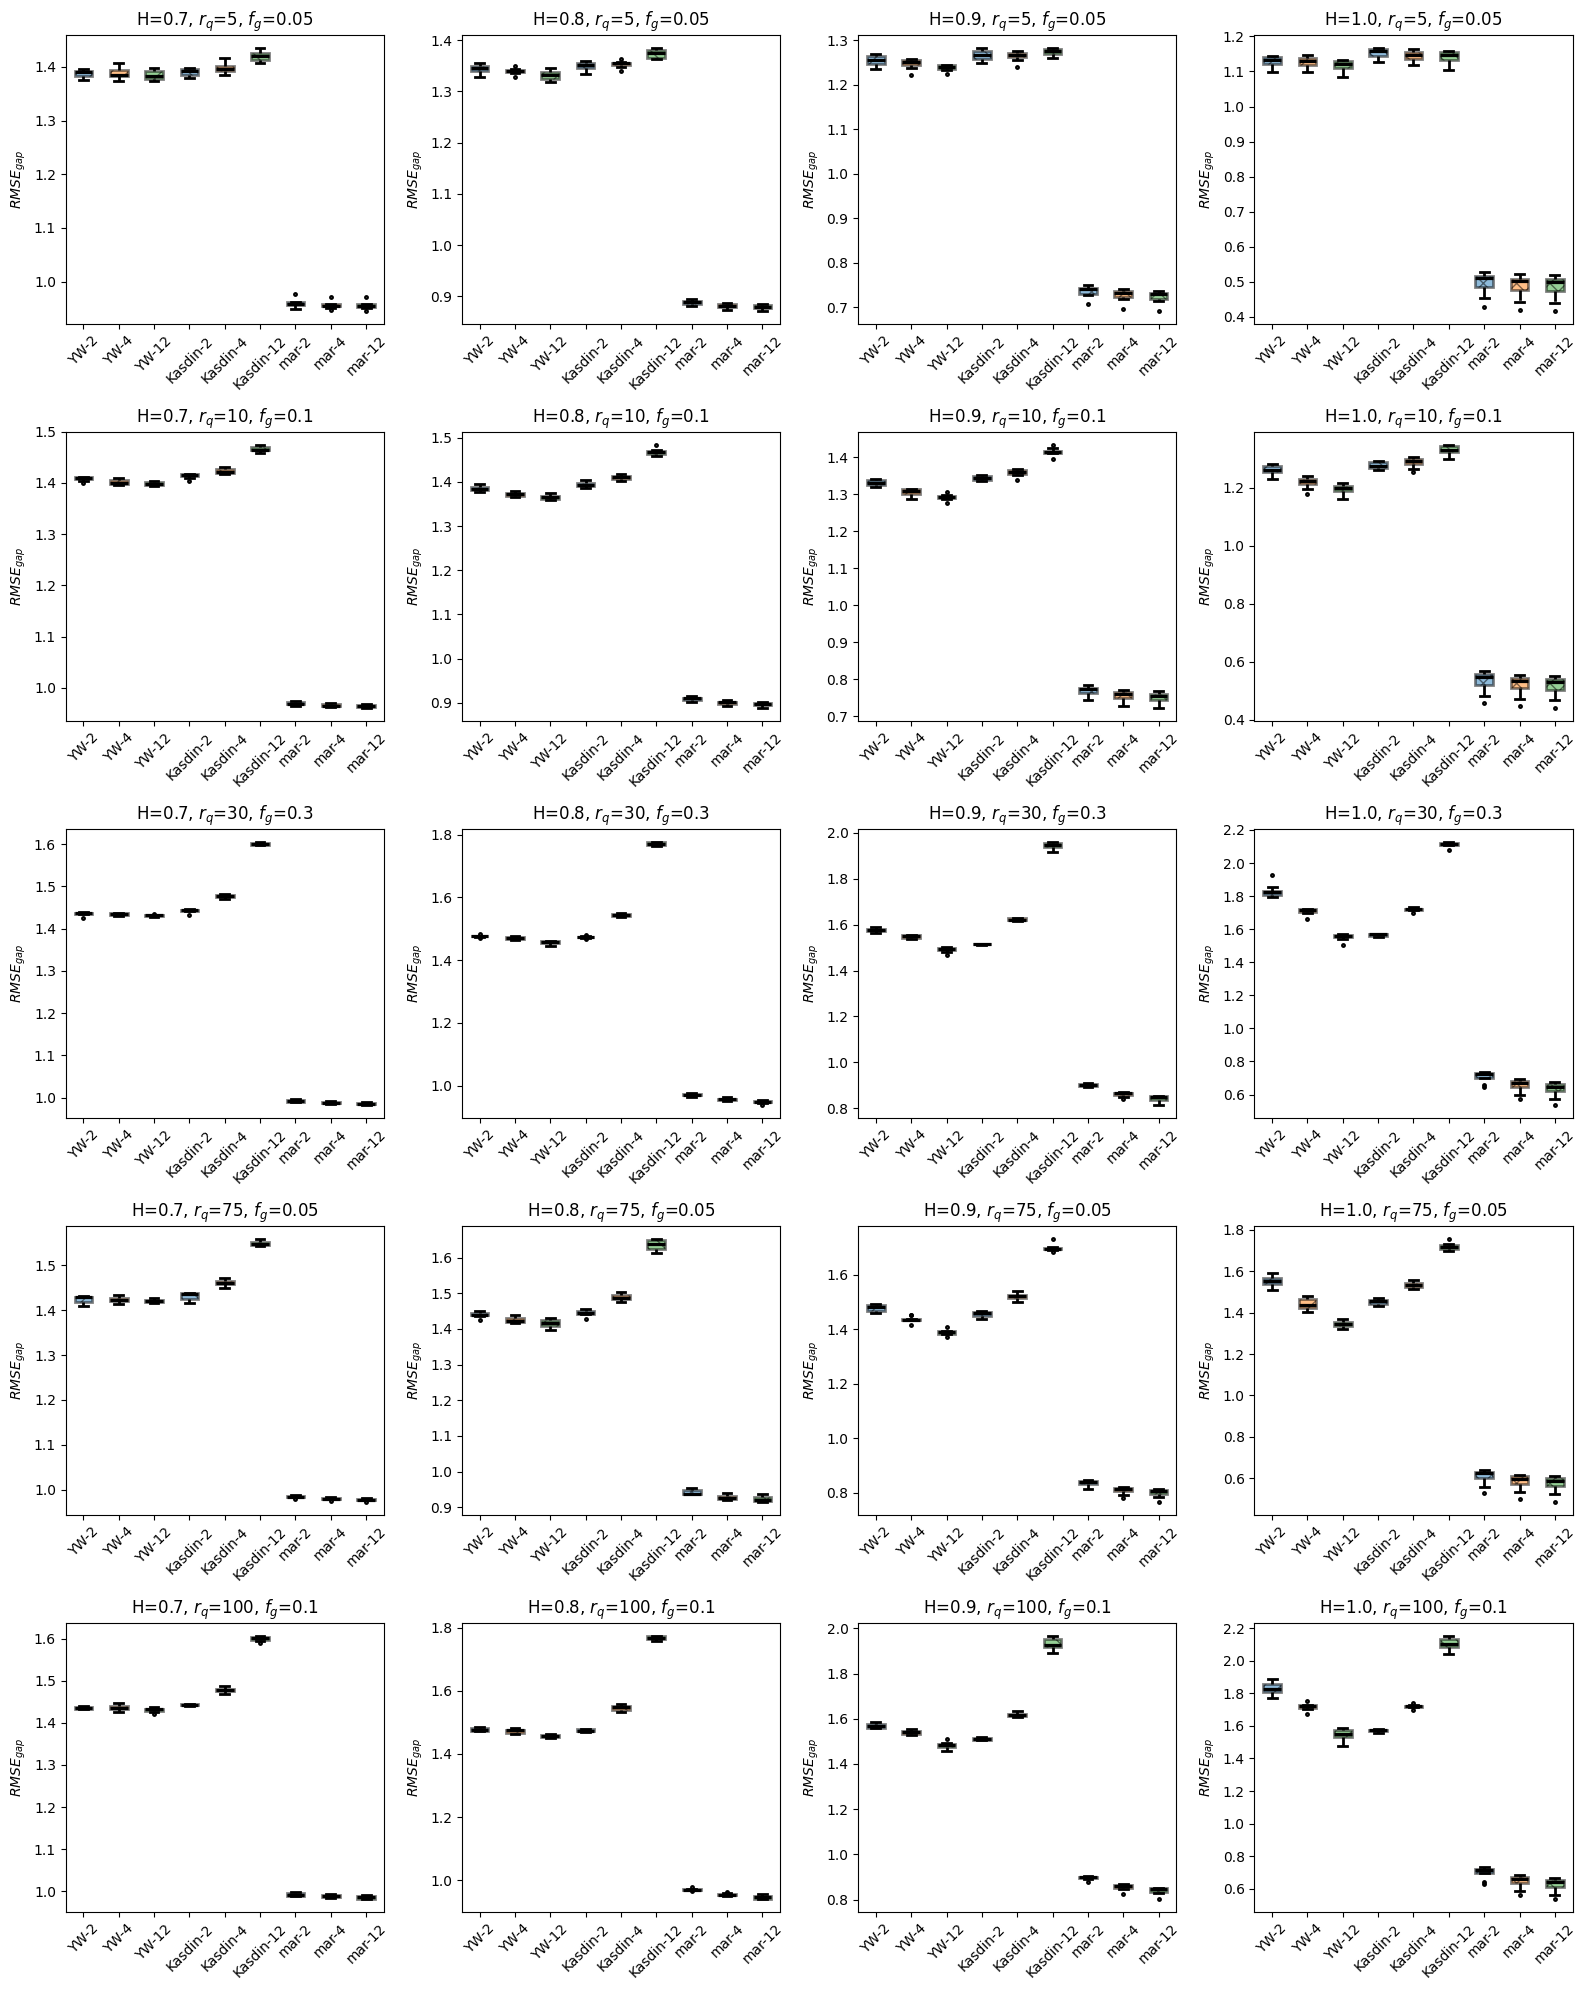

In [ ]:
df = combined_df.reset_index()

box_colors = {f"order={o}": order_colors[o] for o in FILTER_ORDERS}
method_hatch = {"YW": "//", "Kasdin": "\\\\", "mar": "xx"}
methods = ["YW", "Kasdin", "mar"]

h_values = sorted(df["model_h"].unique())
rqfg_values = sorted(
    df[["rq_gap", "fg_gap"]].drop_duplicates().itertuples(index=False, name=None)
)[::4]

n_rows = len(rqfg_values)
n_cols = len(h_values)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharey=False, squeeze=False
)

for row, (rq_gap, fg_gap) in enumerate(rqfg_values):
    for col, model_h in enumerate(h_values):
        ax = axes[row, col]
        group = df[
            (df["model_h"] == model_h)
            & (df["rq_gap"] == rq_gap)
            & (df["fg_gap"] == fg_gap)
        ]

        data = []
        labels = []
        colors = []
        hatches = []
        for method in methods:
            for order in FILTER_ORDERS:
                sub = group[(group["order"] == order) & (group["method"] == method)]
                data.append(sub["rmse_gap"])
                labels.append(f"{method}-{order}")
                colors.append(box_colors[f"order={order}"])
                hatches.append(method_hatch[method])

        bplot = ax.boxplot(data, tick_labels=labels, **boxprops_filled_hatched())
        for patch, color, hatch in zip(bplot["boxes"], colors, hatches):
            patch.set_facecolor(color)
            patch.set_hatch(hatch)
            patch.set_alpha(0.5)

        ax.set_title(f"H={model_h}, $r_q$={rq_gap}, $f_g$={fg_gap}")
        ax.set_ylabel("$RMSE_{gap}$")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()